In [1]:
import polars as pl

abstracts = (
    pl.read_json("/scratch/text/sample-size/fmri-papers.json.gz")
    .select(pl.col("records").explode())
    .unnest("records")
    .select(
        pl.format("{source}:{id}").alias("key"),
        pl.col("pubTypeList"),
        pl.col("journalInfo"),
    )
    .unnest("journalInfo", "pubTypeList")
    .unnest("journal")
    .filter(pl.col("pubType").list.contains("Journal Article"))
)
abstracts

key,pubType,volume,journalIssueId,dateOfPublication,monthOfPublication,yearOfPublication,medlineAbbreviation,title,isoabbreviation,nlmid,essn,issn,printPublicationDate,issue
str,list[str],str,i64,str,i64,i64,str,str,str,str,str,str,str,str
"""MED:42895005""","[""Meta-Analysis"", ""Systematic Review"", … ""Journal Article""]","""40""",4294951,"""2026 Sep""",9,2026,"""J Oral Facial Pain Headache""","""Journal of oral & facial pain …","""J Oral Facial Pain Headache""","""101624698""","""2333-0376""","""2333-0384""","""2026-09-01""","""5"""
"""MED:42861109""","[""Journal Article""]","""16""",4291203,"""2026 Oct""",10,2026,"""Quant Imaging Med Surg""","""Quantitative imaging in medici…","""Quant Imaging Med Surg""","""101577942""","""2223-4306""","""2223-4292""","""2026-10-01""","""10"""
"""MED:42838427""","[""Journal Article""]","""341""",4298550,"""2026 Nov""",11,2026,"""Neuroimage""","""NeuroImage""","""Neuroimage""","""9215515""","""1095-9572""","""1053-8119""","""2026-11-01""",null
"""MED:42786188""","[""research-article"", ""Journal Article""]","""12""",4228983,"""2026 Jul""",7,2026,"""Schizophrenia (Heidelb)""","""Schizophrenia (Heidelberg, Ger…","""Schizophrenia (Heidelb)""","""9918367987006676""","""2754-6993""","""2754-6993""","""2026-07-01""","""1"""
"""MED:42031666""","[""Journal Article""]",null,4276523,"""2026 Oct""",10,2026,"""AJNR Am J Neuroradiol""","""AJNR. American journal of neur…","""AJNR Am J Neuroradiol""","""8003708""","""1936-959X""","""0195-6108""","""2026-10-01""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""MED:1619113""","[""Research Support, Non-U.S. Gov't"", ""Journal Article""]","""91""",600242,"""1992 Jun""",6,1992,"""J Acoust Soc Am""","""The Journal of the Acoustical …","""J Acoust Soc Am""","""7503051""","""1520-8524""","""0001-4966""","""1992-06-01""","""6"""
"""MED:11793145""","[""Journal Article"", ""English Abstract""]","""15""",1044247,"""2001 Dec""",12,2001,"""Schmerz""","""Schmerz (Berlin, Germany)""","""Schmerz""","""8906258""","""1432-2129""","""0932-433X""","""2001-12-01""","""6"""
"""MED:11968459""","[""Research Support, U.S. Gov't, P.H.S."", ""Research Support, Non-U.S. Gov't"", ""Journal Article""]","""89""",1073447,"""2002 """,0,2002,"""Adv Neurol""","""Advances in neurology""","""Adv Neurol""","""0367524""",null,"""0091-3952""","""2002-01-01""",null


In [2]:
disorder = (
    pl.col("icd")
    .replace_strict(
        {
            "F50": "Anorexia nervosa",
            "F31": "Bipolar disorder",
            "F32": "Major depressive disorder",
            "F33": "Major depressive disorder",
            # "F90": "Attention-deficit hyperactivity disorder",
            "F20": "Schizophrenia",
            "F42": "Obsessive-compulsive disorder",
            "F43": "Post-traumatic stress disorder",
            "G40": "Epilepsy",
            "F84": "Autism spectrum disorder",
        },
        default=None,
    )
    .alias("disorder")
)

In [3]:
import json
from pathlib import Path

corrections = json.loads(Path("sample-size-corrections.json").read_text())
corrected_sample_sizes = (
    pl.DataFrame(
        [
            {
                "key": key,
                "case_sample_size": correction["patients"],
                "control_sample_size": correction["controls"],
            }
            for key, correction in corrections["correct"].items()
        ]
    )
    .with_columns(
        pl.col("key").str.extract_groups(r"^(?P<key>[^:]+:[^:]+)(?::(?P<icd>[^:]+))?$")
    )
    .unnest("key")
    .with_columns(disorder)
)

corrected_sample_sizes

key,icd,case_sample_size,control_sample_size,disorder
str,str,i64,i64,str
"""MED:33540370""",null,683,618,null
"""MED:35895072""",null,634,702,null
"""MED:36471870""",null,655,393,null
"""MED:37858907""",null,1016,1479,null
"""MED:38298781""",null,239,239,null
…,…,…,…,…
"""MED:34521980""","""F20""",537,708,"""Schizophrenia"""
"""MED:34521980""","""F84""",778,957,"""Autism spectrum disorder"""
"""MED:23774715""",null,360,403,null


In [4]:
from typing import Any, Literal

from pydantic import BaseModel, ValidationError


class Diagnosis(BaseModel):
    supporting_quotes: list[str]
    reported_diagnosis: str
    icd10_code: str | None
    sample_size: int | None


class Classification(BaseModel):
    eligibility_explanation: str
    diagnoses: list[Diagnosis]
    control_sample_size: int | None
    human_case_control_fmri: Literal["yes", "no", "unclear"]


def parse(row: tuple[str, str]) -> tuple[str, dict[str, Any] | None]:
    key, text = row
    try:
        return key, Classification.model_validate_json(text).model_dump()
    except ValidationError:
        return key, None


def date_to_year(data_frame: pl.DataFrame) -> pl.DataFrame:
    return (
        data_frame.with_columns(
            year_start=pl.date(pl.col("date").dt.year(), 1, 1),
            next_year_start=pl.date(pl.col("date").dt.year() + 1, 1, 1),
        )
        .with_columns(
            year=(
                pl.col("date").dt.year()
                + (
                    (pl.col("date") - pl.col("year_start")).dt.total_days()
                    / (pl.col("next_year_start") - pl.col("year_start")).dt.total_days()
                )
            )
        )
        .drop("date", "year_start", "next_year_start")
        .sort("year")
    )


effective_sample_size = (
    4.0 / ((1.0 / pl.col("case_sample_size")) + (1.0 / pl.col("control_sample_size")))
).alias("effective_sample_size")
classifications = (
    pl.read_ndjson(
        "/scratch/text/sample-size/classified-abstracts-gemini-3.8-flash/*.jsonl.gz"
    )
    .unnest("response")
    .select(pl.col("key"), pl.col("candidates").explode())
    .unnest("candidates")
    .select(pl.col("key"), pl.col("content").explode())
    .unnest("content")
    .select(pl.col("key"), pl.col("parts").explode())
    .unnest("parts")
    .select(pl.col("key"), pl.col("text"))
    .map_rows(parse)
    .unnest("column_1")
    .filter(
        pl.col("human_case_control_fmri")
        .eq("yes")
        .or_(pl.col("column_0").is_in(corrected_sample_sizes.get_column("key").to_list()))
    )
    .select(
        pl.col("column_0").alias("key"),
        pl.col("control_sample_size"),
        pl.col("diagnoses"),
    )
    .explode("diagnoses")
    .unnest("diagnoses")
    .select(
        pl.col("key"),
        pl.col("control_sample_size"),
        pl.col("icd10_code").alias("icd"),
        pl.col("sample_size").alias("case_sample_size"),
    )
    # Categories
    .select("key", disorder, "case_sample_size", "control_sample_size")
    .drop_nulls("disorder")
    # Sum
    .group_by("key", "disorder")
    .agg(
        pl.col("case_sample_size").sum(),
        pl.col("control_sample_size").max(),
    )
    .unique(subset=["key", "disorder"])
    # Corrections
    .filter(pl.col("key").is_in(corrections["exclude"].keys()).not_())
    .update(
        corrected_sample_sizes.filter(pl.col("disorder").is_null()).drop(
            "icd", "disorder"
        ),
        on="key",
    )
    .update(
        corrected_sample_sizes.drop_nulls("disorder").drop("icd"),
        on=["key", "disorder"],
    )
    # Effective sample size
    .with_columns(effective_sample_size)
    .filter(pl.col("effective_sample_size") > 0)
    # Date
    .join(
        abstracts.select(
            pl.col("key"),
            pl.col("printPublicationDate").str.to_date().alias("date"),
        ),
        on="key",
        how="inner",
    )
    .drop_nulls("date")
    .pipe(date_to_year)
)
classifications

key,disorder,case_sample_size,control_sample_size,effective_sample_size,year
str,str,i64,i64,f64,f64
"""MED:7997102""","""Schizophrenia""",10,10,20.0,1994.0
"""MED:8092341""","""Schizophrenia""",8,9,16.941176,1994.747945
"""MED:7597160""","""Schizophrenia""",10,10,20.0,1995.246575
"""MED:7582669""","""Schizophrenia""",10,7,16.470588,1995.580822
"""MED:8561199""","""Schizophrenia""",12,11,22.956522,1996.084699
…,…,…,…,…,…
"""MED:41729791""","""Post-traumatic stress disorder""",32,31,62.984127,2026.915068
"""MED:42861136""","""Anorexia nervosa""",20,26,45.217391,2026.915068
"""MED:42772405""","""Schizophrenia""",45,43,87.954545,2026.915068


In [5]:
enigma = (
    pl.DataFrame(
        {
            "key": [
                "MED:41922983",
                "MED:37131072",
                "MED:41880651",
                "MED:40736265",
                "MED:37858907",
                "MED:38298781",
                "MED:40894594",
                "MED:40840859",
                "MED:39725297",
                "ENIGMA-AN",
                "ENIGMA-MDD",
                "ENIGMA-SCZ",
                "ENIGMA-BD",
                "ENIGMA-ASD",
            ],
            "disorder": [
                "Post-traumatic stress disorder",
                "Obsessive-compulsive disorder",
                "Epilepsy",
                "Post-traumatic stress disorder",
                "Post-traumatic stress disorder",
                "Post-traumatic stress disorder",
                "Obsessive-compulsive disorder",
                "Post-traumatic stress disorder",
                "Obsessive-compulsive disorder",
                "Anorexia nervosa",
                "Major depressive disorder",
                "Schizophrenia",
                "Bipolar disorder",
                "Autism spectrum disorder",
            ],
            "case_sample_size": [
                1017,
                1024,
                442,
                336,
                1016,
                239,
                475,
                326,
                633,
                872,
                2106,
                1200,
                900,
                2435,
            ],
            "control_sample_size": [
                1702,
                1028,
                387,
                699,
                1479,
                239,
                345,
                463,
                453,
                1126,
                2777,
                1400,
                900,
                2408,
            ],
            # printPublicationDate from Europe PMC
            "date": [
                "2026-05-01",
                "2023-10-01",
                "2026-03-01",
                "2025-08-01",
                "2023-12-01",
                "2024-01-01",
                "2025-08-01",
                "2026-06-01",
                "2025-08-01",
                None,
                None,
                None,
                None,
                None,
            ],
        }
    )
    .with_columns(pl.col("date").str.to_date())
    .pipe(date_to_year)
    .with_columns(effective_sample_size)
    .select(classifications.columns)
)
enigma

key,disorder,case_sample_size,control_sample_size,effective_sample_size,year
str,str,i64,i64,f64,f64
"""ENIGMA-AN""","""Anorexia nervosa""",872,1126,1965.70971,null
"""ENIGMA-MDD""","""Major depressive disorder""",2106,2777,4790.794184,null
"""ENIGMA-SCZ""","""Schizophrenia""",1200,1400,2584.615385,null
"""ENIGMA-BD""","""Bipolar disorder""",900,900,1800.0,null
"""ENIGMA-ASD""","""Autism spectrum disorder""",2435,2408,4842.849473,null
…,…,…,…,…,…
"""MED:40894594""","""Obsessive-compulsive disorder""",475,345,799.390244,2025.580822
"""MED:39725297""","""Obsessive-compulsive disorder""",633,453,1056.165746,2025.580822
"""MED:41880651""","""Epilepsy""",442,387,825.351025,2026.161644


In [6]:
import numpy as np
import statsmodels.nonparametric.smoothers_lowess


def lowess_with_confidence_bounds(x, y, eval_x, N=200, conf_interval=0.95, **lowess_kw):
    """
    Perform Lowess regression and determine a confidence interval by bootstrap resampling
    """
    rng = np.random.default_rng(seed=0)

    lowess_kw = lowess_kw or {}
    # Lowess smoothing
    smoothed = statsmodels.nonparametric.smoothers_lowess.lowess(
        exog=x, endog=y, xvals=eval_x, **lowess_kw
    )

    # Perform bootstrap resamplings of the data
    # and  evaluate the smoothing at a fixed set of points
    smoothed_values = np.empty((N, len(eval_x)))
    for i in range(N):
        sample = rng.choice(len(x), len(x), replace=True)
        sampled_x = x[sample]
        sampled_y = y[sample]

        smoothed_values[i] = statsmodels.nonparametric.smoothers_lowess.lowess(
            exog=sampled_x, endog=sampled_y, xvals=eval_x, **lowess_kw
        )

    # Get the confidence interval
    sorted_values = np.sort(smoothed_values, axis=0)
    bound = int(N * (1 - conf_interval) / 2)
    bottom = sorted_values[bound - 1]
    top = sorted_values[-bound]

    return smoothed, bottom, top

In [7]:
x = (
    classifications.filter(pl.col("disorder").is_in({"Epilepsy"}).not_())
    .get_column("year")
    .to_numpy()
)
y = (
    classifications.filter(pl.col("disorder").is_in({"Epilepsy"}).not_())
    .get_column("effective_sample_size")
    .to_numpy()
)

lowess_x = np.linspace(x.min(), x.max(), 100)
lowess_y, lower, upper = lowess_with_confidence_bounds(
    x, y, lowess_x, frac=0.2, conf_interval=0.95
)

labels = (
    classifications.sort("disorder")
    .group_by("disorder", maintain_order=True)
    .agg(pl.len())
    .select(pl.format("{disorder} ({len})"))
    .to_series()
)
print(lowess_y[-1])
labels

108.74224677284538


disorder
str
"""Anorexia nervosa (280)"""
"""Autism spectrum disorder (790)"""
"""Bipolar disorder (789)"""
"""Epilepsy (769)"""
"""Major depressive disorder (211…"
"""Obsessive-compulsive disorder …"
"""Post-traumatic stress disorder…"
"""Schizophrenia (2038)"""


/work/charite/thesis/defense/images/.pixi/envs/default/lib/python3.15/site-packages/colorspacious/comparison.py:11: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  """Computes the :math:`\Delta E` distance between pairs of colors.


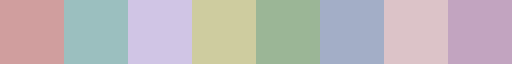

In [8]:
import glasbey
import matplotlib.colors

cmap = matplotlib.colors.ListedColormap(
    glasbey.create_palette(
        palette_size=len(labels),
        grid_space="JCh",
        lightness_bounds=(62, 75),
        chroma_bounds=(10, 20),
        hue_bounds=(80, 20),
        colorblind_safe=False,
    )
)
cmap

In [9]:
(
    classifications.sort("disorder")
    .select(pl.col("disorder").unique(maintain_order=True))
    .join(enigma, on="disorder", how="left", maintain_order="left")
    .group_by("disorder", maintain_order=True)
    .agg(
        pl.col("case_sample_size", "control_sample_size", "effective_sample_size").max()
    )
    .filter(pl.col("disorder").ne("Epilepsy"))
    .write_csv("enigma.csv")
)

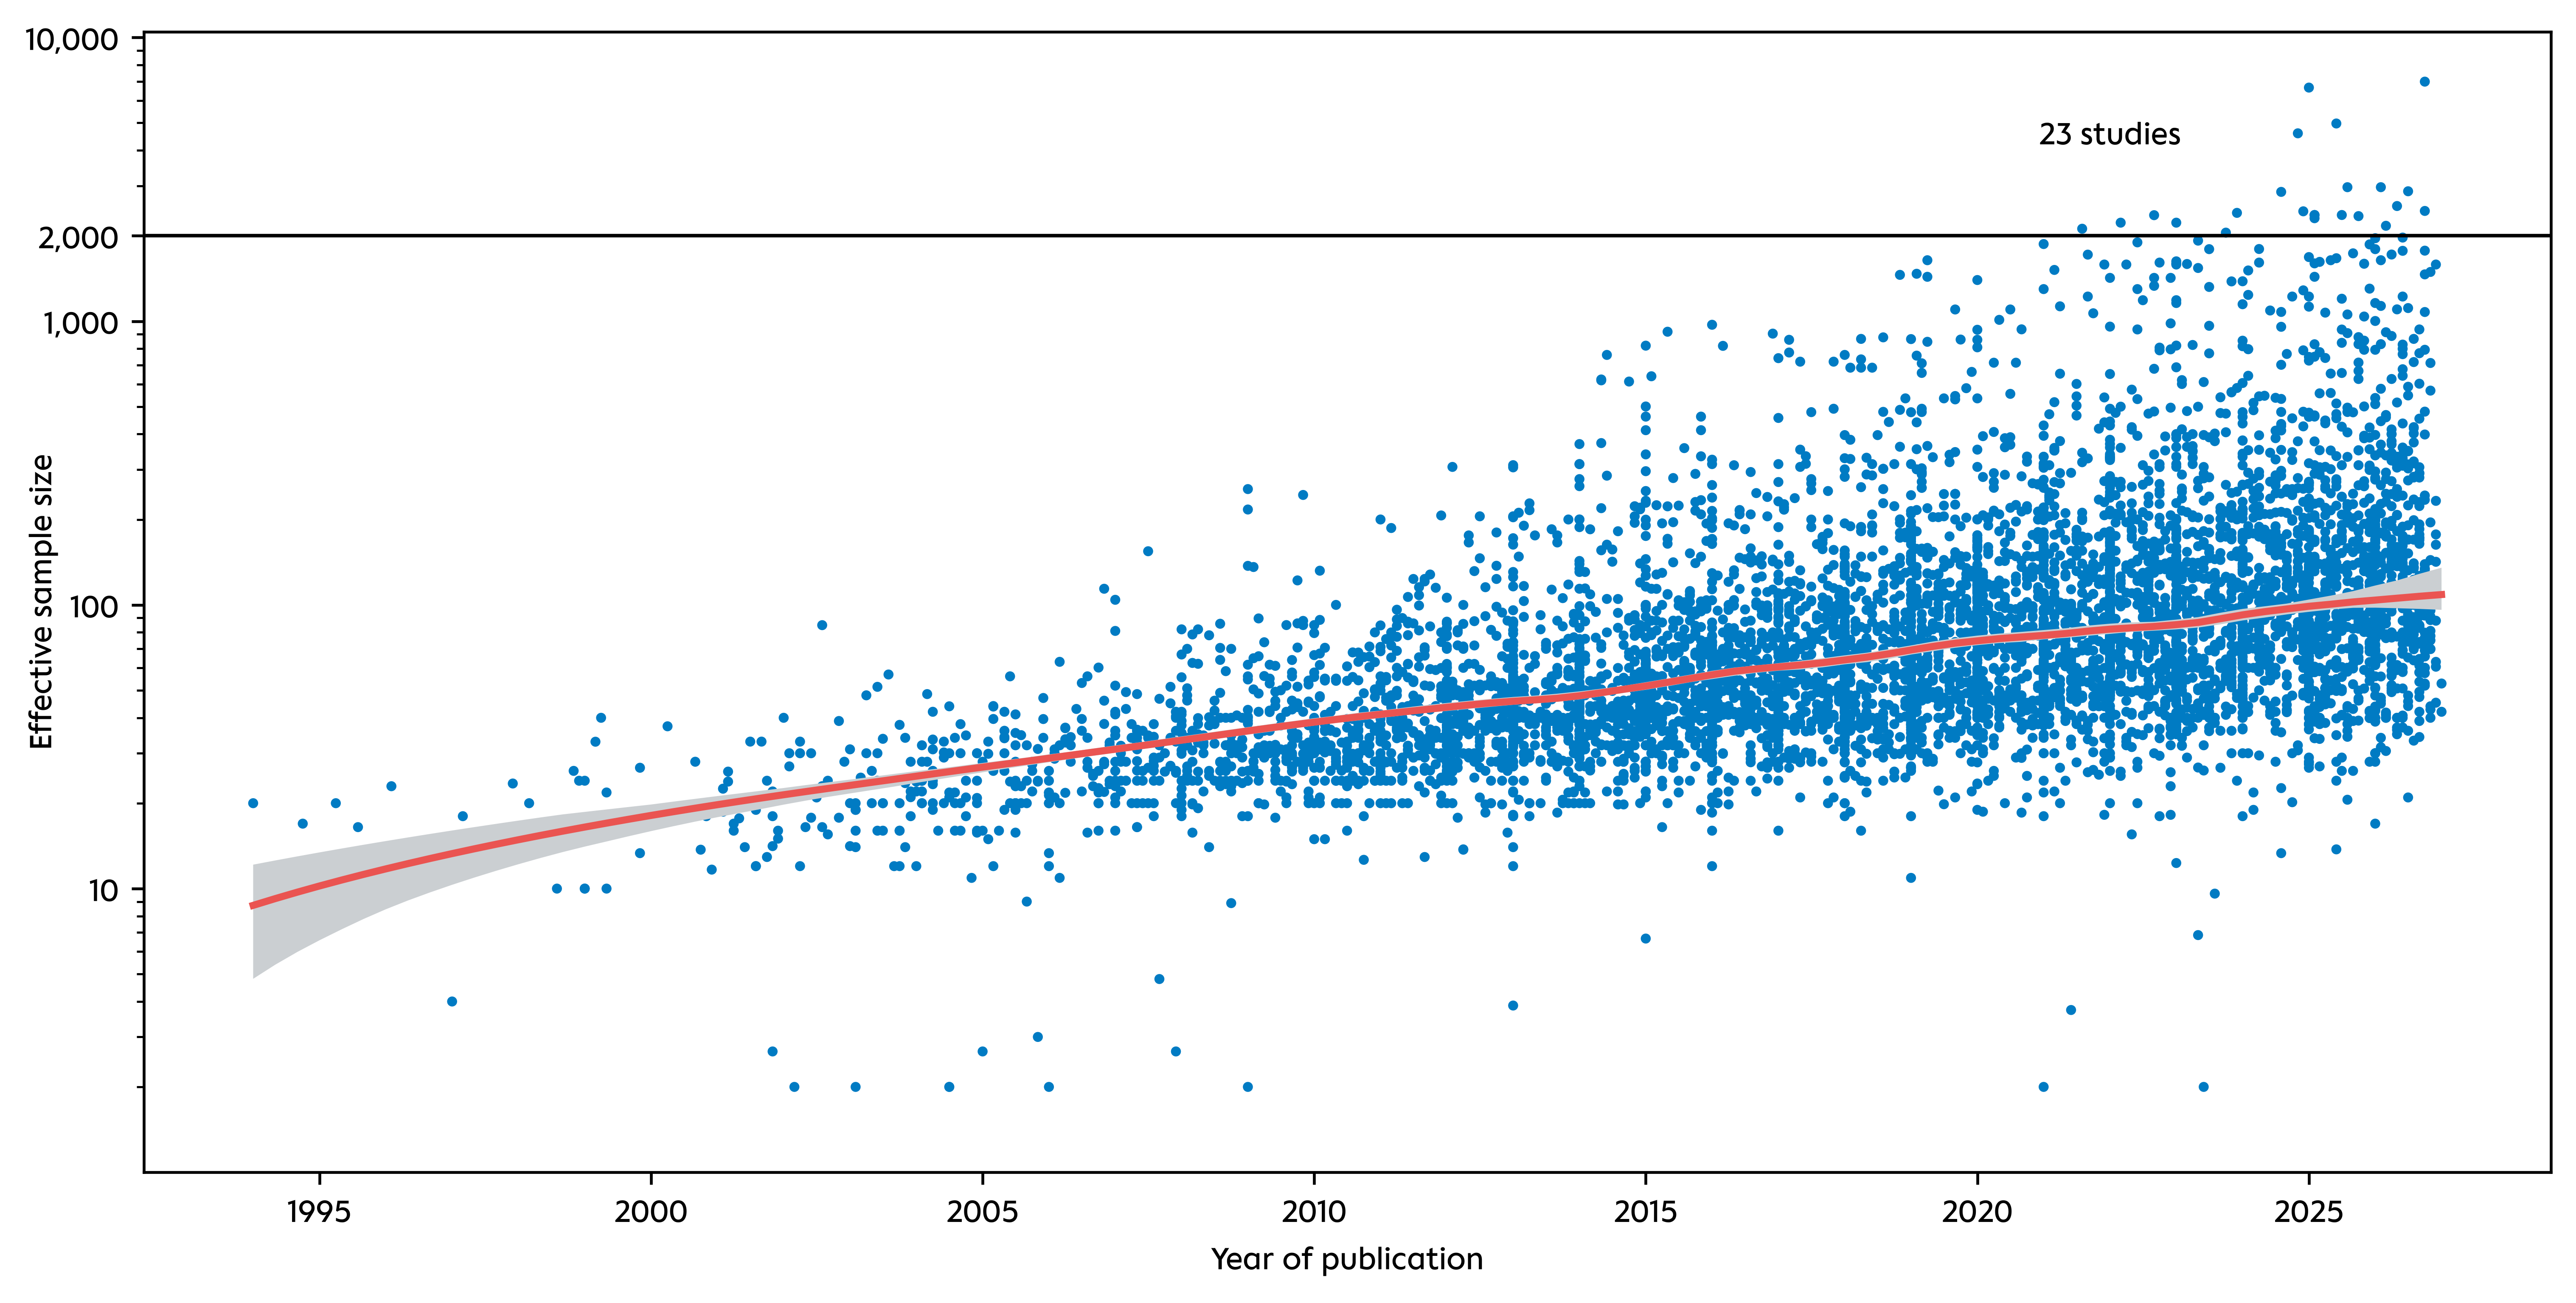

In [10]:
import numpy as np
from charite_plot.brands.charite import KORALL, PRIME_LGREY, SECOND_LBLUE
from matplotlib import pyplot as plt

font_family = "Charité Text Office"
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": [f"{font_family}"],
        "mathtext.fontset": "custom",
        "mathtext.rm": f"{font_family}",
        "mathtext.it": f"{font_family}:italic",
        "mathtext.bf": f"{font_family}:bold",
        "mathtext.bfit": f"{font_family}:bold:italic",
        "mathtext.sf": f"{font_family}",
    }
)

figure, axes = plt.subplots(
    nrows=1, ncols=1, figsize=(10, 5), dpi=600, constrained_layout=True
)

path_collection = axes.scatter(
    x=x,
    y=y,
    marker="o",
    s=8.0,
    # alpha=0.5,
    # c=classifications.get_column("disorder").rank("dense").to_numpy(),
    # cmap=cmap,
    c=SECOND_LBLUE,
    edgecolor="none",
)
# handles, _ = path_collection.legend_elements()
# axes.legend(
#     handles=handles,
#     labels=labels,
#     framealpha=1.0,
# )

# path_collection = axes.scatter(
#     x=enigma.get_column("year").to_numpy(),
#     y=enigma.get_column("effective_sample_size").to_numpy(),
#     marker="x",
#     s=25.0,
#     c=enigma.get_column("disorder").rank("dense").to_numpy(),
#     cmap=cmap,
#     zorder=10,
#     label="HALFpipe",
# )

axes.plot(lowess_x, lowess_y, linewidth=2.0, color=KORALL)
axes.fill_between(lowess_x, lower, upper, facecolor=PRIME_LGREY)

axes.axhline(y=2_000, linewidth=1.0, color="#000000")

axes.annotate(
    f"{(y > 2_000).sum()} studies",
    xy=(2022, (2_000 + y.max()) * 0.5),
    horizontalalignment="center",
    verticalalignment="center",
)

axes.set_yscale("log")

axes.set_xlabel("Year of publication")
axes.set_ylabel("Effective sample size")
axes.yaxis.set_label_coords(-0.035, 0.5)

axes.set_ylim(1.0, y.max() * 1.5)
axes.set_yticks(
    [10, 100, 1_000, 2_000, 10_000], labels=["10", "100", "1,000", "2,000", "10,000"]
)

# axes.set_title(
#     "Case-control studies in major psychiatric disorders",
#     fontsize="x-large",
#     # loc="left",
#     # pad=0.5,
# )

figure.savefig("actual.svg", bbox_inches="tight", pad_inches=0, transparent=True)

In [11]:
classifications.filter(pl.col("effective_sample_size") > 2_000).sort(
    "effective_sample_size", descending=True
).get_column("key").to_list()

['MED:42144135',
 'MED:39670402',
 'MED:40172866',
 'MED:39588672',
 'MED:40628558',
 'MED:41672980',
 'MED:42477489',
 'MED:39117859',
 'MED:41922983',
 'MED:42906847',
 'MED:39776853',
 'MED:37858907',
 'MED:39915482',
 'MED:39973062',
 'MED:40710624',
 'MED:36130921',
 'MED:41135842',
 'MED:39566747',
 'MED:35338312',
 'MED:36878150',
 'MED:41811439',
 'MED:34282889',
 'MED:37131072']

In [12]:
classifications.filter(pl.col("key") == "MED:39511450")

key,disorder,case_sample_size,control_sample_size,effective_sample_size,year
str,str,i64,i64,f64,f64
"""MED:39511450""","""Major depressive disorder""",848,794,1640.224117,2025.328767
"""MED:39511450""","""Post-traumatic stress disorder""",130,268,350.150754,2025.328767


In [13]:
(
    classifications.sort("effective_sample_size", descending=True, nulls_last=True)
    .group_by("disorder", maintain_order=True)
    .first()
)

disorder,key,case_sample_size,control_sample_size,effective_sample_size,year
str,str,i64,i64,f64,f64
"""Major depressive disorder""","""MED:42144135""",1923,19107,6988.637375,2026.747945
"""Post-traumatic stress disorder""","""MED:41922983""",1017,1702,2546.427363,2026.328767
"""Schizophrenia""","""MED:42906847""",1223,1224,2446.999591,2026.747945
"""Obsessive-compulsive disorder""","""MED:37131072""",1024,1028,2051.992203,2023.747945
"""Autism spectrum disorder""","""MED:42141307""",940,1036,1971.336032,2026.413699
"""Epilepsy""","""MED:41880651""",442,387,825.351025,2026.161644
"""Bipolar disorder""","""MED:24778245""",300,324,623.076923,2014.328767
"""Anorexia nervosa""","""MED:40480995""",151,461,454.973856,2025.413699


In [14]:
top = (
    enigma.sort("effective_sample_size", descending=True, nulls_last=True)
    .group_by("disorder", maintain_order=True)
    .first()
    .sort(
        by=(pl.col("year").is_not_null(), "effective_sample_size"),
        descending=True,
        nulls_last=True,
    )
    .select("disorder", "effective_sample_size")
)
top = pl.concat(
    (
        top,
        classifications.sort("effective_sample_size", descending=True, nulls_last=True)
        .group_by("disorder", maintain_order=True)
        .first()
        .select("disorder", "effective_sample_size")
        .filter(pl.col("disorder").is_in(top.get_column("disorder").to_list()).not_())
        .sort("effective_sample_size", descending=True, nulls_last=True),
    )
)
top

disorder,effective_sample_size
str,f64
"""Post-traumatic stress disorder""",2546.427363
"""Obsessive-compulsive disorder""",2051.992203
"""Epilepsy""",825.351025
"""Autism spectrum disorder""",4842.849473
"""Major depressive disorder""",4790.794184
"""Schizophrenia""",2584.615385
"""Anorexia nervosa""",1965.70971
"""Bipolar disorder""",1800.0


In [42]:
abbreviations = {
    "Anorexia nervosa": "AN",
    "Bipolar disorder": "BD",
    "Major depressive disorder": "MDD",
    "Schizophrenia": "SCZ",
    "Obsessive-compulsive disorder": "OCD",
    "Post-traumatic stress disorder": "PTSD",
    "Autism spectrum disorder": "ASD",
}

collaborators: dict[str, list[tuple[str, Path | None]]] = {
    "Anorexia nervosa": [
        (
            "Clara El Khantour",
            Path(
                "/scratch/imaging/collaborator-pictures/anorexia-clara-el-khantour.jpg"
            ),
        ),
        (
            "Clara Moreau",
            Path("/scratch/imaging/collaborator-pictures/anorexia-clara-moreau.jpg"),
        ),
        (
            "Stefan Ehrlich",
            Path("/scratch/imaging/collaborator-pictures/anorexia-stefan-ehrlich.jpg"),
        ),
    ],
    "Bipolar disorder": [
        (
            "Melody Kang",
            Path("/scratch/imaging/collaborator-pictures/bipolar-melody-kang.jpg"),
        ),
        (
            "Leila Nabulsi",
            Path("/scratch/imaging/collaborator-pictures/bipolar-leila-nabulsi.jpg"),
        ),
        (
            "Dara Cannon",
            Path("/scratch/imaging/collaborator-pictures/bipolar-dara-cannon.jpg"),
        ),
        (
            "Chris Ching",
            Path("/scratch/imaging/collaborator-pictures/bipolar-chris-ching.jpg"),
        ),
    ],
    "Major depressive disorder": [
        (
            "Elena Pozzi",
            Path("/scratch/imaging/collaborator-pictures/mdd-elena-pozzi.jpg"),
        ),
        (
            "Lianne Schmaal",
            Path("/scratch/imaging/collaborator-pictures/mdd-lianne-schmaal.jpg"),
        ),
    ],
    "Schizophrenia": [
        (
            "Theo van Erp",
            Path("/scratch/imaging/collaborator-pictures/scz-theo-van-erp.jpg"),
        ),
        (
            "Jess Turner",
            Path("/scratch/imaging/collaborator-pictures/scz-jess-turner.jpg"),
        ),
    ],
    "Obsessive-compulsive disorder": [
        (
            "Nadza Džinalija",
            Path("/scratch/imaging/collaborator-pictures/ocd-nadza-dzinalija.jpg"),
        ),
        (
            "Chris Vriend",
            Path("/scratch/imaging/collaborator-pictures/ocd-chris-vriend.jpg"),
        ),
        (
            "Odile van den Heuvel",
            Path("/scratch/imaging/collaborator-pictures/ocd-odile-van-den-heuvel.jpg"),
        ),
    ],
    "Post-traumatic stress disorder": [
        (
            "Courtney Russell",
            Path("/scratch/imaging/collaborator-pictures/ptsd-courtney-russell.jpg"),
        ),
        (
            "Jenni Stevens",
            Path("/scratch/imaging/collaborator-pictures/ptsd-jenni-stevens.jpg"),
        ),
        (
            "Delin Sun",
            Path("/scratch/imaging/collaborator-pictures/ptsd-delin-sun.jpg"),
        ),
        (
            "Raj Morey",
            Path("/scratch/imaging/collaborator-pictures/ptsd-raj-morey.jpg"),
        ),
    ],
    "Autism spectrum disorder": [
        ("Gaon Kim", Path("/scratch/imaging/collaborator-pictures/asd-gaon-kim.jpg")),
    ],
    "Epilepsy": [
        ("Vicky Ives-Deliperi", None),
        ("Jonathan Ipser", None),
    ],
}

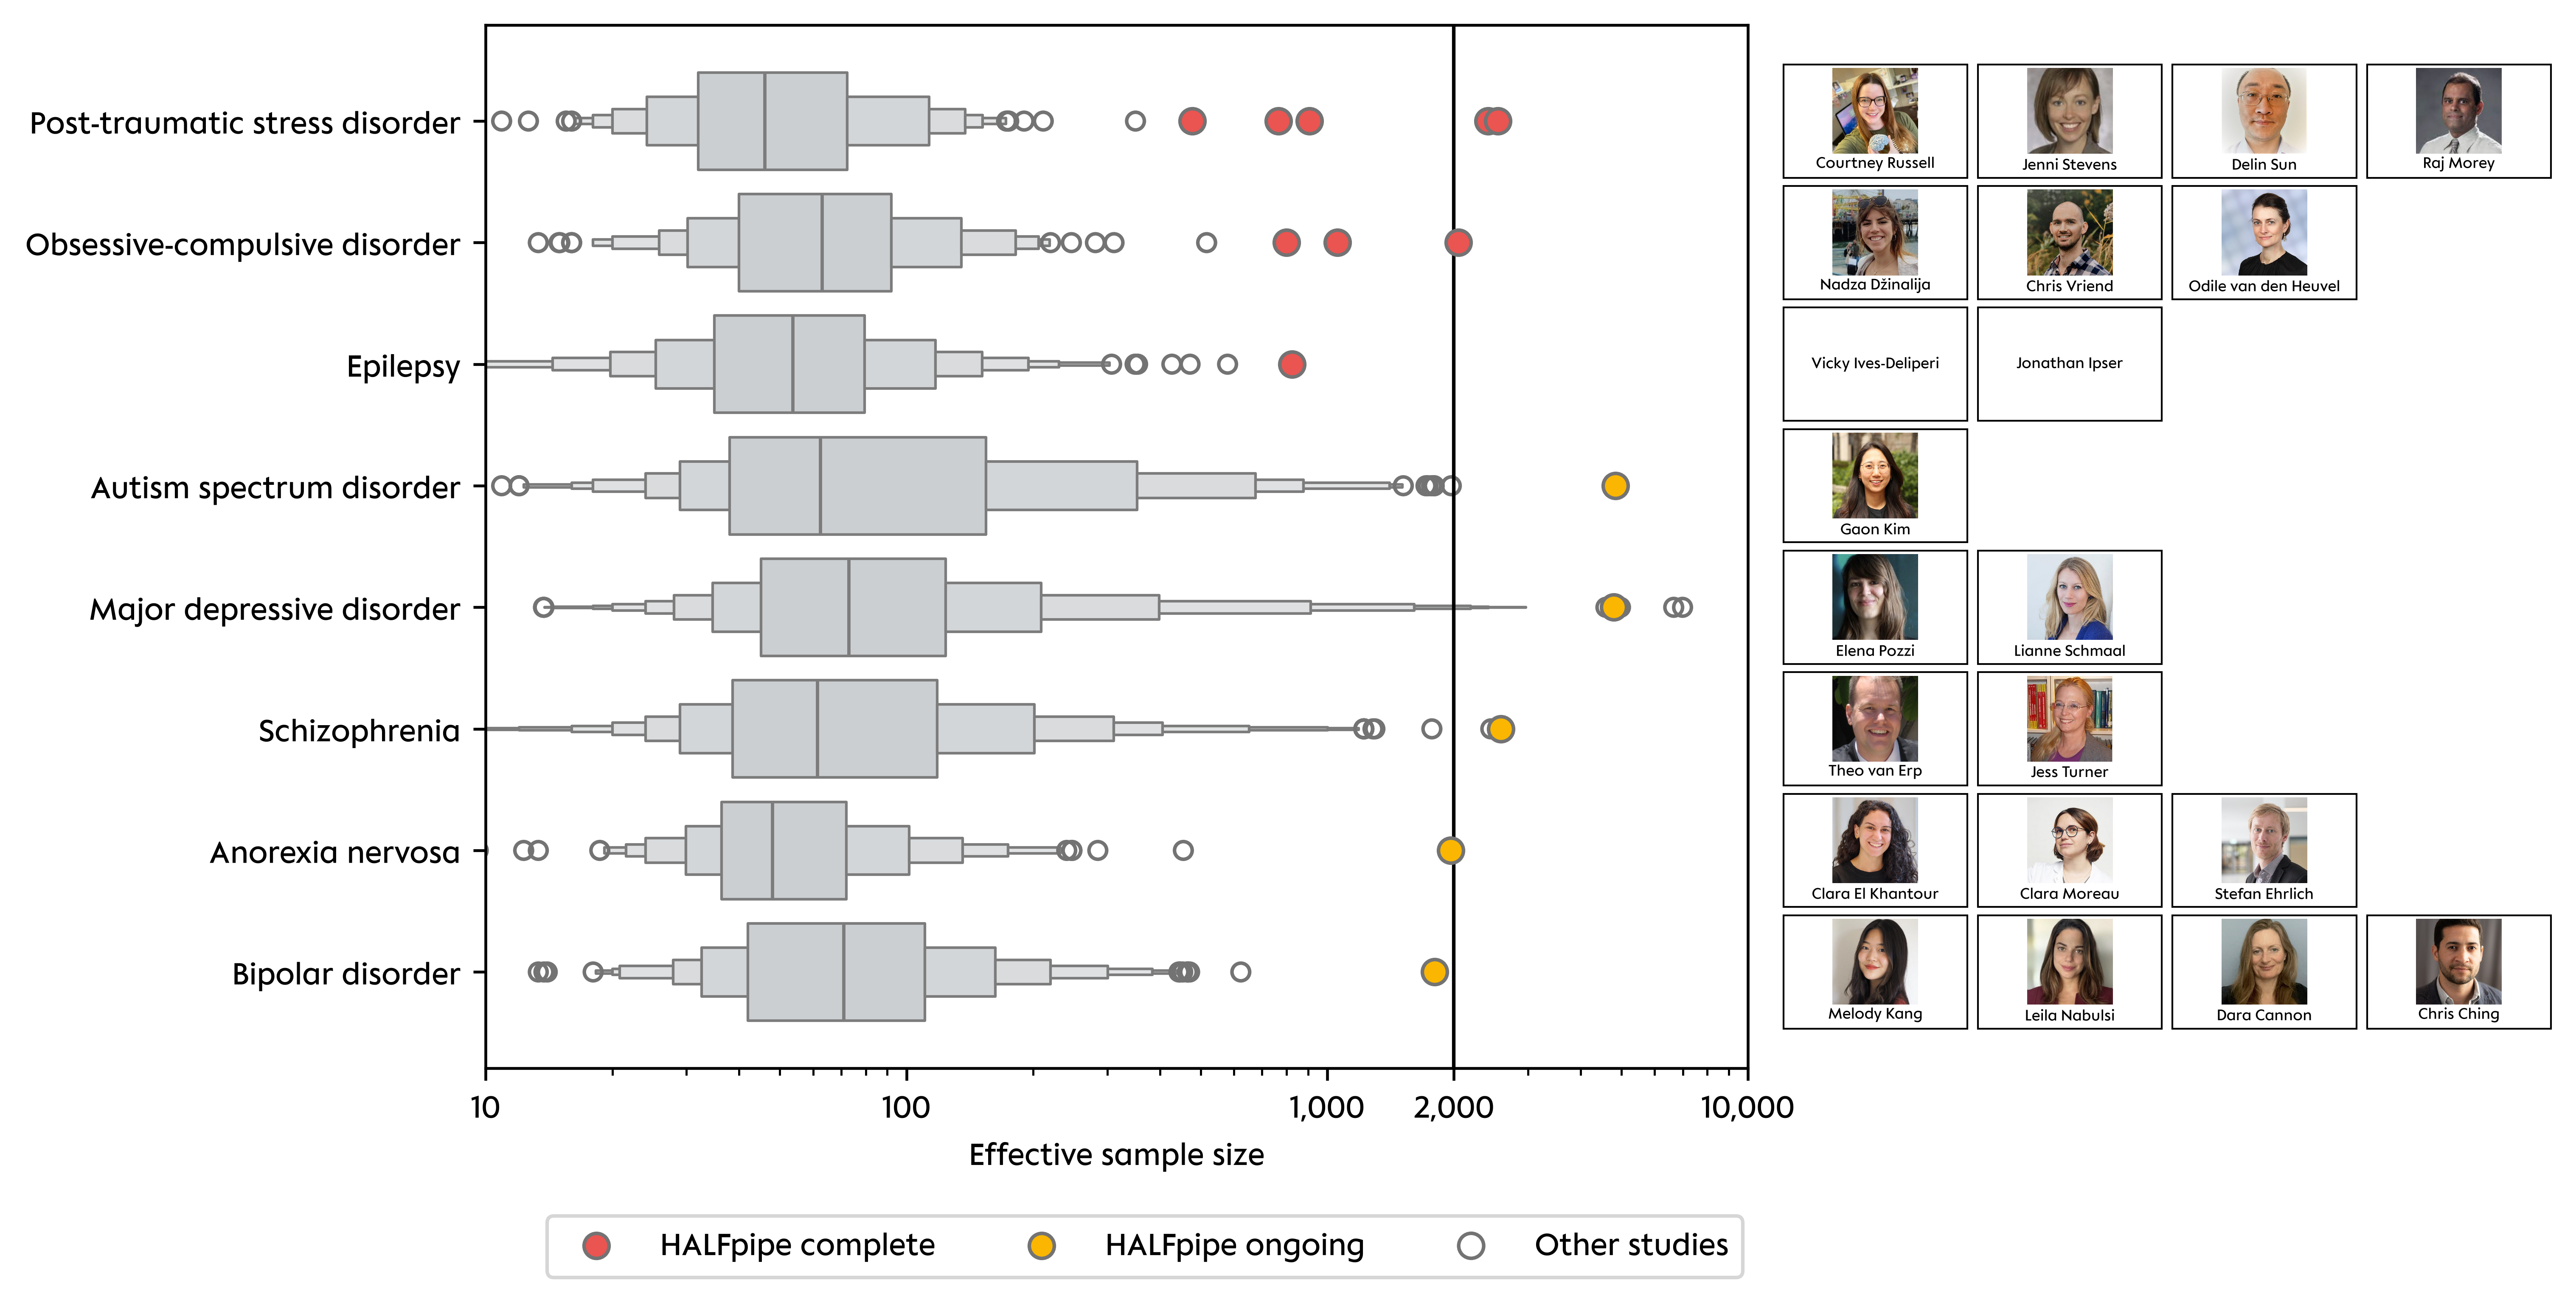

In [64]:
import textwrap

import matplotlib.offsetbox
import matplotlib.text
import seaborn as sns
from charite_plot.brands.charite import KORALL, MANGO

labels = (
    classifications.get_column("disorder").sort().unique(maintain_order=True).to_list()
)

figure, axes = plt.subplots(
    nrows=1,
    ncols=1,
    figsize=(10, 5),
    dpi=600,
    constrained_layout=True,
    sharey=True,
)

width = 30
wrapped_disorder = pl.col("disorder").map_elements(
    lambda text: "\n".join(textwrap.wrap(text, width=width))
)

palette = list(cmap.colors)  # pyright: ignore[reportArgumentType]
ordered = top.get_column("disorder").unique(maintain_order=True).to_list()
positions = {disorder: position for position, disorder in enumerate(ordered)}
order = ["\n".join(textwrap.wrap(disorder, width=width)) for disorder in ordered]
sns.boxenplot(
    data=classifications.filter(
        pl.col("key").is_in(enigma.get_column("key").to_list()).not_(),
    )
    .with_columns(wrapped_disorder)
    .to_pandas(),
    y="disorder",
    x="effective_sample_size",
    ax=axes,
    log_scale=True,
    order=order,
    color=PRIME_LGREY,
    # hue="disorder",
    # hue_order=order,
    # palette=[palette[labels.index(disorder)] for disorder in ordered],
    k_depth="tukey",
)

panel_enigma = enigma.filter(pl.col("year").is_null().not_())
axes.scatter(
    y=panel_enigma.get_column("disorder").replace_strict(positions).to_numpy(),
    x=panel_enigma.get_column("effective_sample_size").to_numpy(),
    marker="o",
    s=50.0,
    edgecolor="0.45",
    c=KORALL,
    zorder=10,
    label="HALFpipe complete",
)
panel_enigma = enigma.filter(pl.col("year").is_null())
axes.scatter(
    y=panel_enigma.get_column("disorder").replace_strict(positions).to_numpy(),
    x=panel_enigma.get_column("effective_sample_size").to_numpy(),
    marker="o",
    s=50.0,
    edgecolor="0.45",
    c=MANGO,
    zorder=10,
    label="HALFpipe ongoing",
)

axes.scatter(
    x=[],
    y=[],
    marker="o",
    s=50.0,
    edgecolor="0.45",
    c="none",
    zorder=10,
    label="Other studies",
)

axes.axvline(x=2_000, linewidth=1.0, color="#000000")

axes.set_ylabel("")

axes.set_xlim(10.0, x.max() * 1.5)
axes.set_xticks(
    [10, 100, 1_000, 2_000, 10_000],
    labels=["10", "100", "1,000", "2,000", "10,000"],
)

axes.legend(
    loc="upper right",
    bbox_to_anchor=(1.01, -0.125),
    ncol=3,
)

# axes.set_title(
#     "Completed projects",
#     fontsize="x-large",
#     loc="left",
#     pad=0.5,
# )

axes.set_xlabel("Effective sample size")
# axes.xaxis.set_label_coords(-0.04, 0.5)


name_fontsize = 5
name_height = name_fontsize * 1.15

tile_height = 30
picture_size = tile_height - name_height
tile_width = 50

tile_offset = 10
tile_spacing = 5


def name_text(name: str, x: float, y: float) -> matplotlib.text.Text:
    return matplotlib.text.Text(
        x,
        y,
        name,
        horizontalalignment="center",
        verticalalignment="center",
        fontsize=name_fontsize,
        linespacing=1.1,
    )


def collaborator_tile(name: str, picture: Path | None):
    if picture is None:  # grey box with the name centered
        area = matplotlib.offsetbox.DrawingArea(tile_width, tile_height)
        area.add_artist(name_text(name, tile_width / 2, tile_height / 2))
        children = [area]
    else:
        image = matplotlib.image.imread(picture)
        image = matplotlib.offsetbox.OffsetImage(
            image, zoom=picture_size / image.shape[1]
        )  # zoom maps pixels to points
        label = matplotlib.offsetbox.DrawingArea(tile_width, name_height)
        label.add_artist(name_text(name, tile_width / 2, name_height / 2))
        children = [image, label]
    return matplotlib.offsetbox.VPacker(
        children=children, pad=1.0, sep=0, align="center"
    )


for position, disorder in enumerate(ordered):
    for index, (name, picture) in enumerate(collaborators.get(disorder, [])):
        axes.add_artist(
            matplotlib.offsetbox.AnnotationBbox(
                collaborator_tile(name, picture),
                xy=(1.0, position),
                xycoords=axes.get_yaxis_transform(),  # x in axes, y in data coordinates
                xybox=(tile_offset + index * (tile_width + tile_spacing), 0.0),
                boxcoords="offset points",
                box_alignment=(0.0, 0.5),
                pad=0,
                # the frame is the outline and the grey background behind the name
                bboxprops={
                    "boxstyle": "square,pad=0",
                    # "facecolor": PRIME_LGREY,
                    # "edgecolor": edgecolor,
                    "linewidth": 0.5,
                },
                annotation_clip=False,
            )
        )

figure.savefig("halfpipe.svg", bbox_inches="tight", pad_inches=0.001, transparent=True)

In [40]:
axes.get_ylim(), axes.get_yticklabels(), y

((np.float64(7.79), np.float64(-0.79)),
 [Text(0, 0, 'Post-traumatic stress disorder'),
  Text(0, 1, 'Obsessive-compulsive disorder'),
  Text(0, 2, 'Epilepsy'),
  Text(0, 3, 'Autism spectrum disorder'),
  Text(0, 4, 'Major depressive disorder'),
  Text(0, 5, 'Schizophrenia'),
  Text(0, 6, 'Anorexia nervosa'),
  Text(0, 7, 'Bipolar disorder')],
 {0: 'Post-traumatic stress disorder',
  1: 'Obsessive-compulsive disorder',
  2: 'Epilepsy',
  3: 'Autism spectrum disorder',
  4: 'Major depressive disorder',
  5: 'Schizophrenia',
  6: 'Anorexia nervosa',
  7: 'Bipolar disorder'})

In [17]:
import pandas as pd

large_studies = (
    pl.read_json("large-studies.json")
    .drop("description")
    .unnest("studies")
    .transpose()
    .unnest("column_0")
    .drop("evidence")
)

consortia = pd.Series(
    [
        "ENIGMA/\nHALFpipe"
        if "ENIGMA" in large_study
        else ("DIRECT" if large_study == "REST-meta-MDD" else large_study)
        for large_study in (
            large_study[0] if len(large_study) == 1 else "Multiple\nsources"
            for large_study in large_studies.get_column("name").to_list()
        )
    ]
)
counts: dict[str, int] = consortia.value_counts().to_dict()  # pyright: ignore[reportAssignmentType]

In [18]:
counts

{'DIRECT': 11,
 'Multiple\nsources': 4,
 'ENIGMA/\nHALFpipe': 3,
 'DIDA-MDD': 3,
 'UK Biobank': 2}

PermissionError: [Errno 13] Permission denied: 'pie.png'

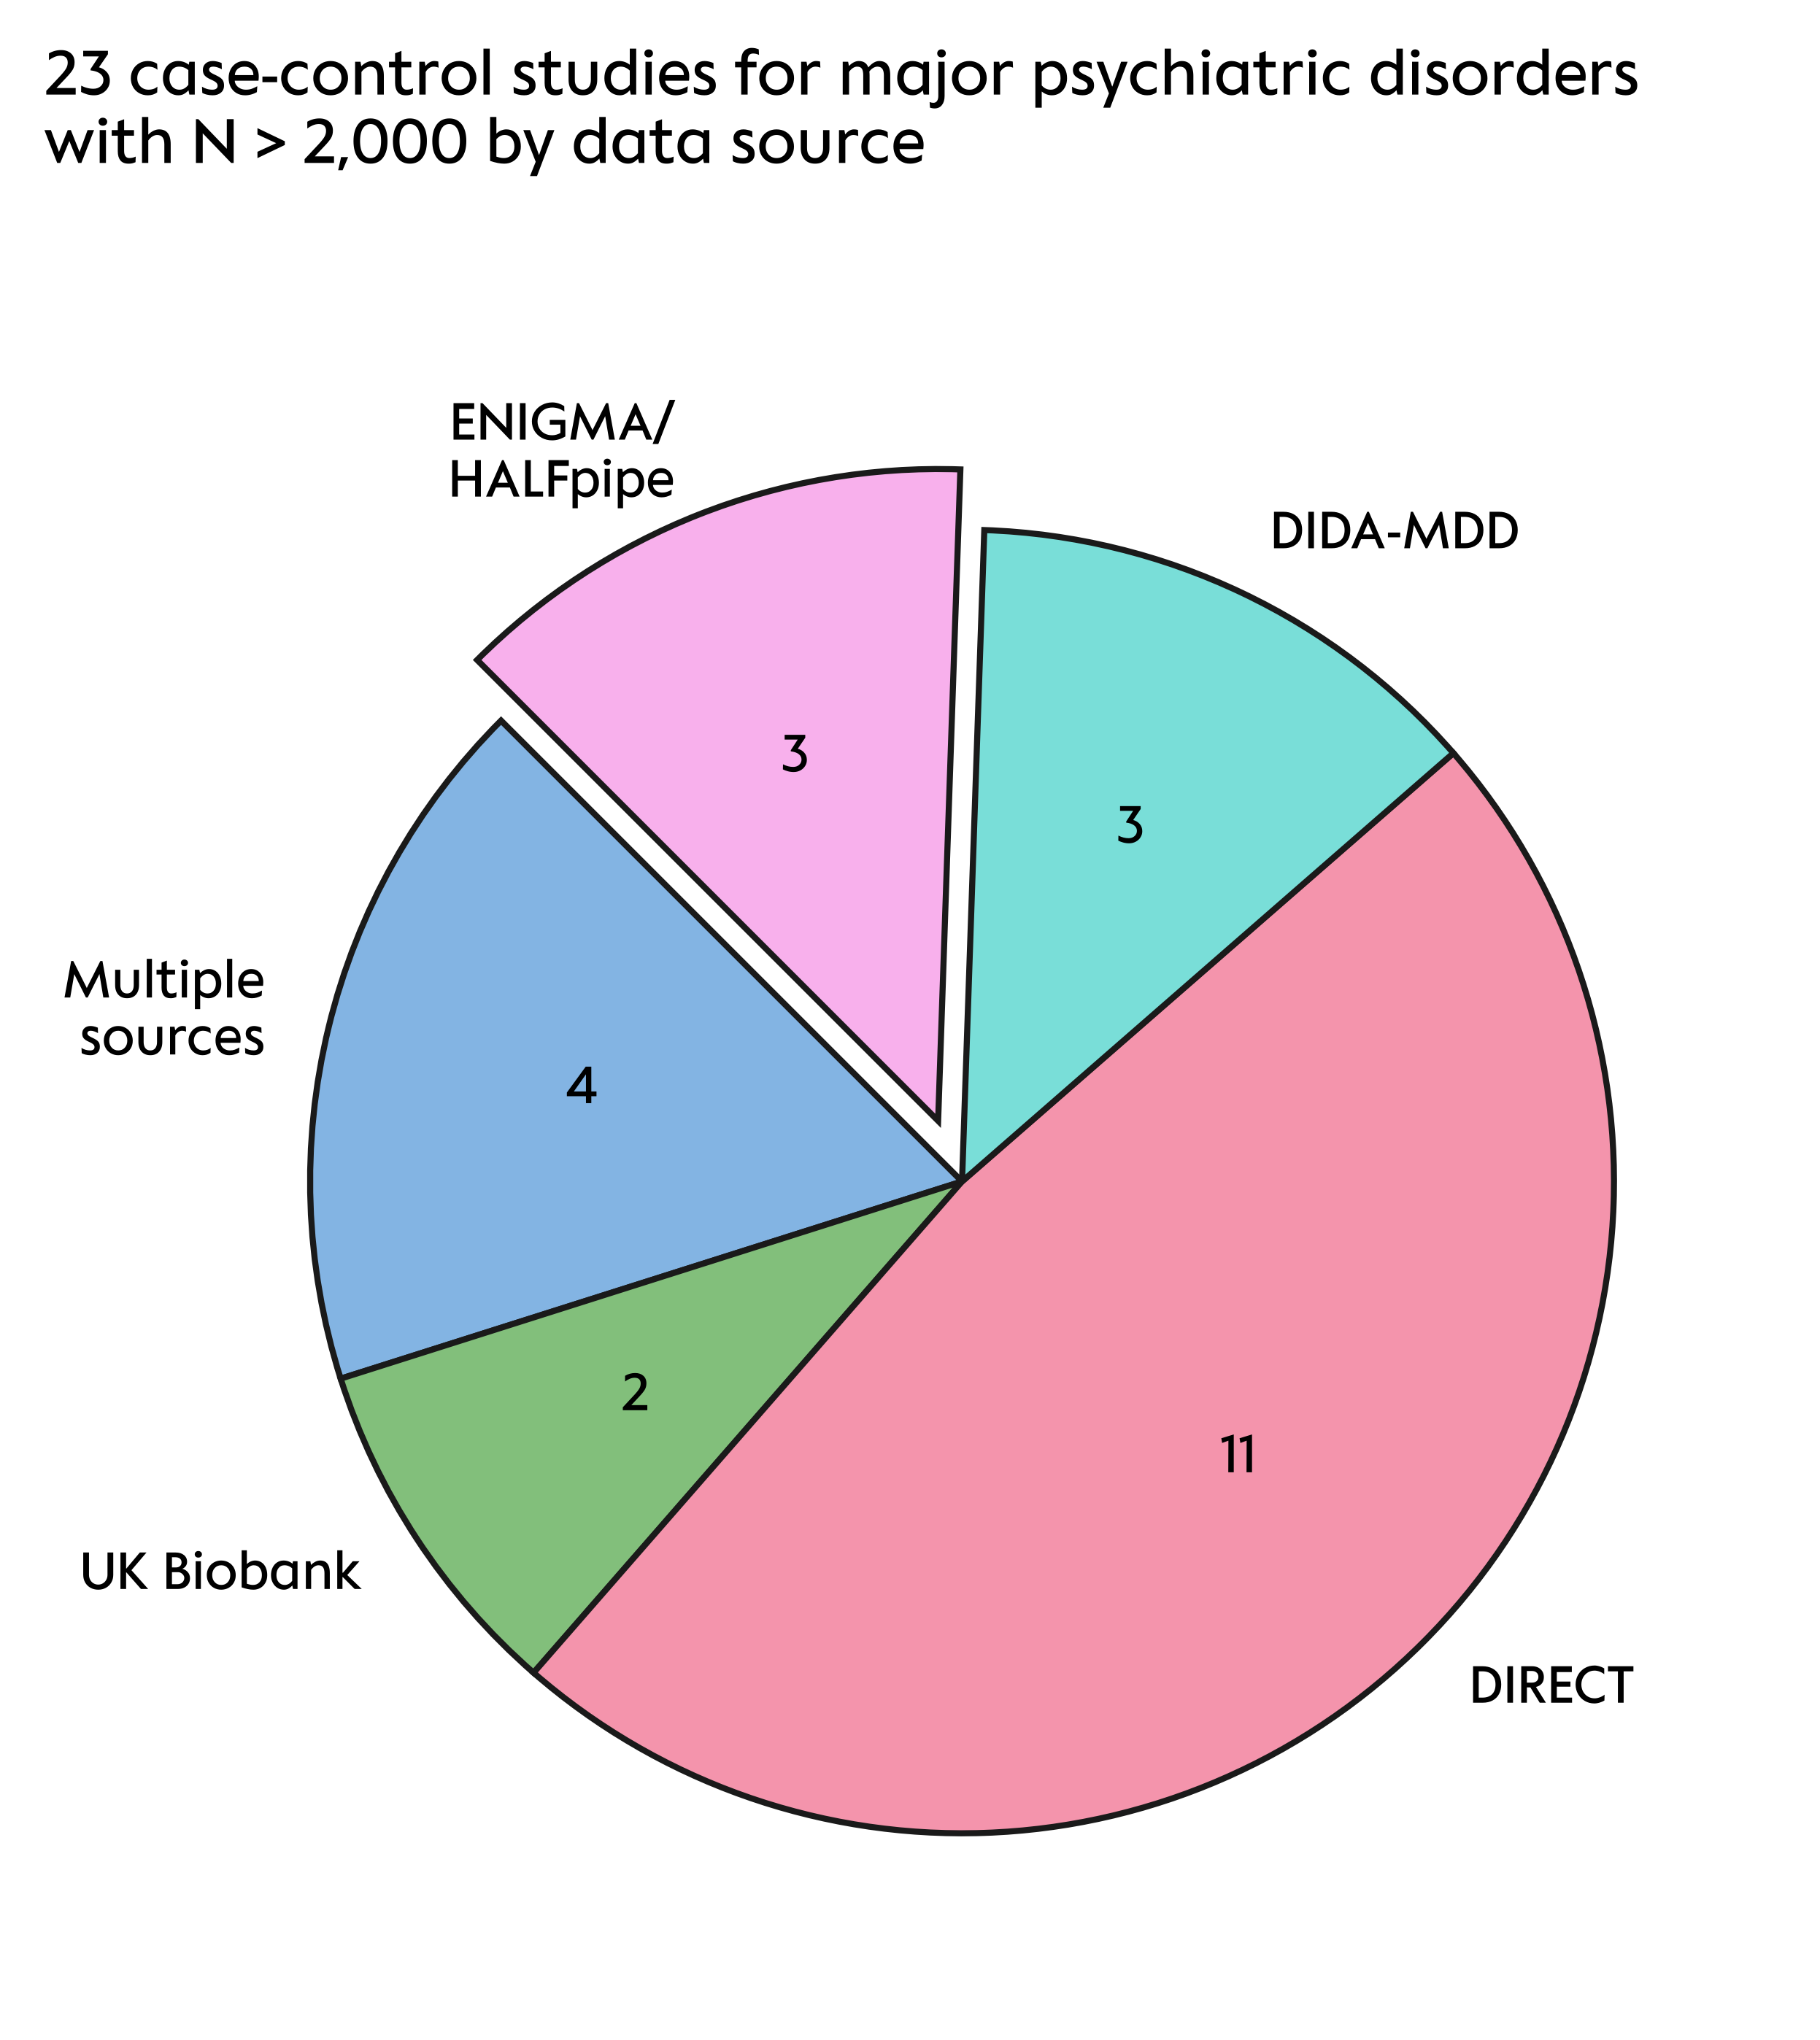

In [19]:
figure, axes = plt.subplots(
    nrows=1,
    ncols=1,
    figsize=(4, 4),
    dpi=600,
    layout="constrained",
    sharey=True,
)

keys = [
    "ENIGMA/\nHALFpipe",
    "DIDA-MDD",
    "DIRECT",
    # "REST-meta-MDD",
    "UK Biobank",
    "Multiple\nsources",
][::-1]
axes.pie(
    [counts[key] for key in keys],
    explode=(0.0,) * (len(keys) - 1) + (0.1,),
    labels=keys,
    autopct=lambda percent: f"{percent / 100 * sum(counts.values()):.0f}",
    startangle=135,
    wedgeprops={"edgecolor": "0.1", "linewidth": 1.0},
    colors=glasbey.create_palette(
        palette_size=len(counts),
        grid_space="JCh",
        lightness_bounds=(62, 75),
        chroma_bounds=(30, 40),
        hue_bounds=(140, 20),
        colorblind_safe=True,
    ),  # pyright: ignore[reportArgumentType]
)

figure.suptitle(
    f"{sum(counts.values())} case-control studies for major psychiatric disorders\n"
    f"with N > 2,000 by data source",
    # fontsize="x-large",
    x=0.0,
    horizontalalignment="left",
    y=1.15,
)

figure.savefig(
    "pie.png",
    dpi=600,
    bbox_inches="tight",
)